615 coins, 188,805 coin pairs, 5 methods
                  min  median     max     std  share_at_modal_value
Copula         0.0000  0.4023  1.0012  0.1624                0.0435
HMM           -0.9451  0.7304  1.0000  0.3065                0.0333
GLASSO         0.4481  0.5000  0.6707  0.0030                0.9828
DTW            0.2863  0.3679  1.0000  0.0432                0.0001
Cointegration  0.0000  0.0103  1.0000  0.0067                0.0506


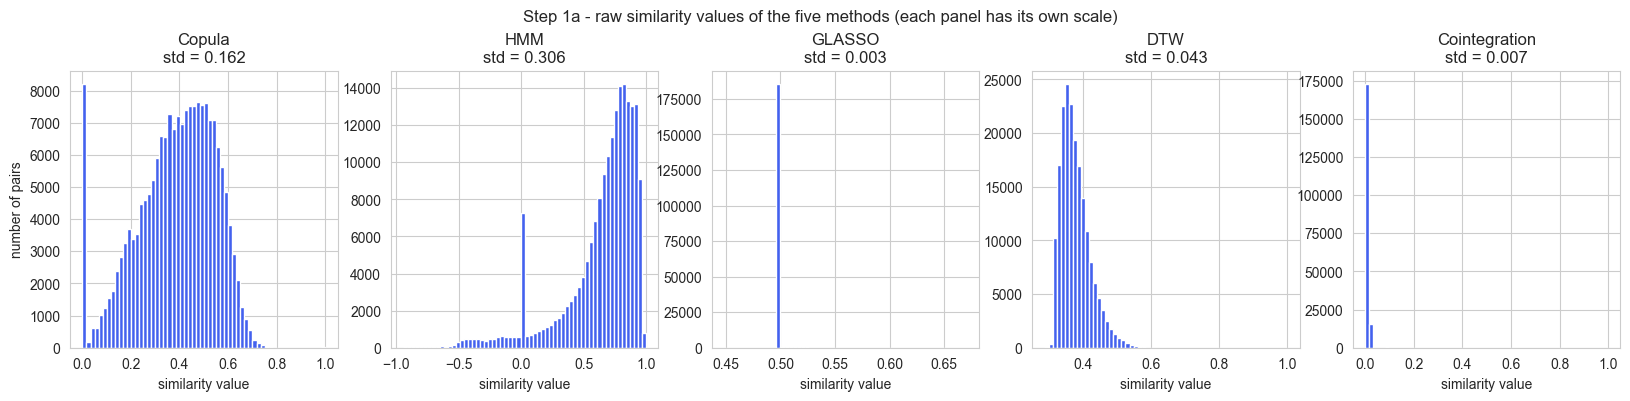


Spearman correlation between the combined score and each method:
               plain average of raw values  Borda (rank average)
Copula                               0.820                 0.831
HMM                                  0.805                 0.660
GLASSO                               0.100                 0.153
DTW                                  0.726                 0.799
Cointegration                        0.246                 0.524


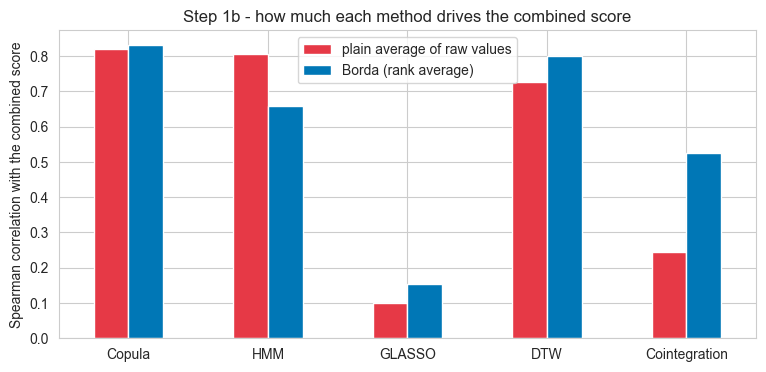


Spread of influence (max - min):  plain average = 0.720,  Borda = 0.679
A smaller spread means the methods count more equally.
Max absolute difference vs saved composite: 2.93e-04
Spearman correlation vs saved composite   : 1.000000
WARNING - the saved composite was built differently.


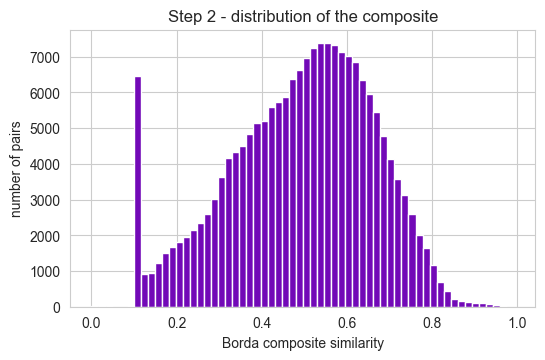

Recomputed Borda groups vs thesis file, ARI = 1.000

Cluster sizes, largest first:
                           Copula  HMM  GLASSO  DTW  Cointegration  Borda
cluster 1 (largest first)     260  478     491  197            325    232
cluster 2 (largest first)     167   99      48  157            206    208
cluster 3 (largest first)      99   23      46  151             82    117
cluster 4 (largest first)      89   15      30  110              2     58


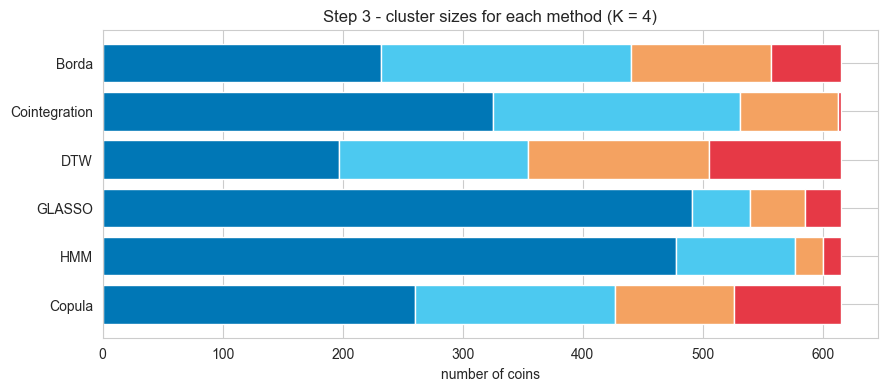

Number of pairs by how many methods put them together:
0     9938
1    40670
2    62898
3    48540
4    21519
5     5240


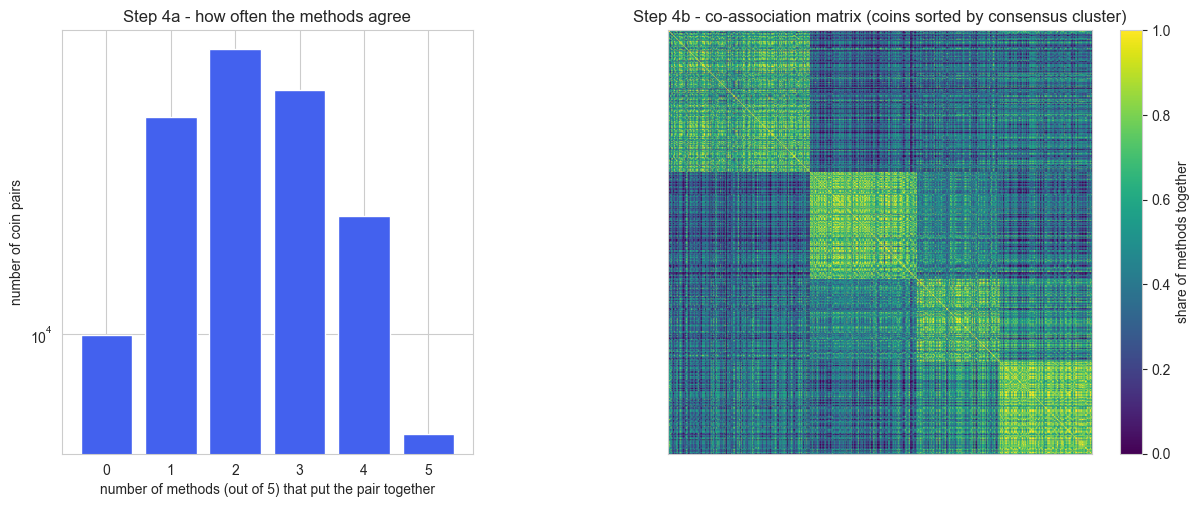

Borda vs Consensus ARI: 0.351
Share of pairs treated the same way (together or apart): 73.8% (inflated, because most pairs are 'apart' in both)
Coins sitting in a matched cell: 55.6%


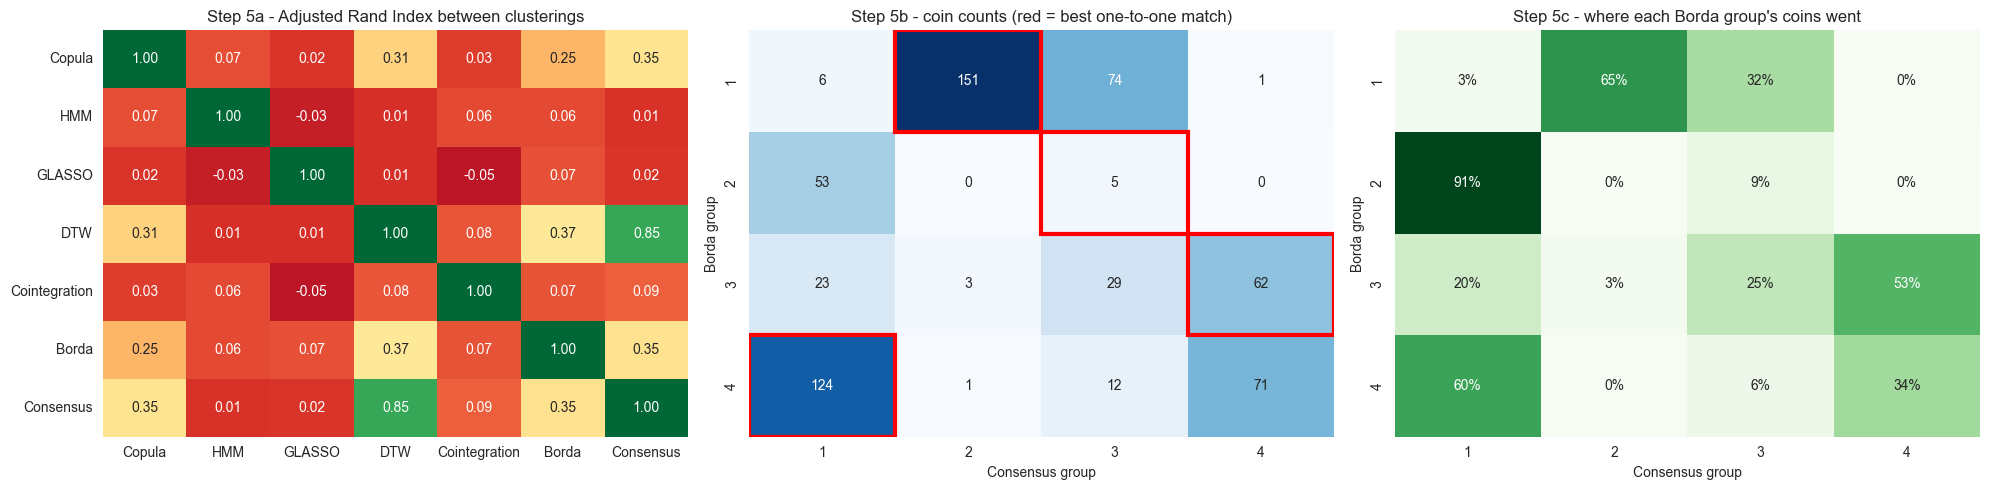

 K  ARI_borda_vs_consensus
 3                   0.275
 4                   0.351
 5                   0.236
 6                   0.242
 7                   0.262
 8                   0.232

Running 100 coin-subsample repeats (this takes a minute or two)...
Bootstrap ARI: mean 0.341, 95% interval [0.187, 0.518]


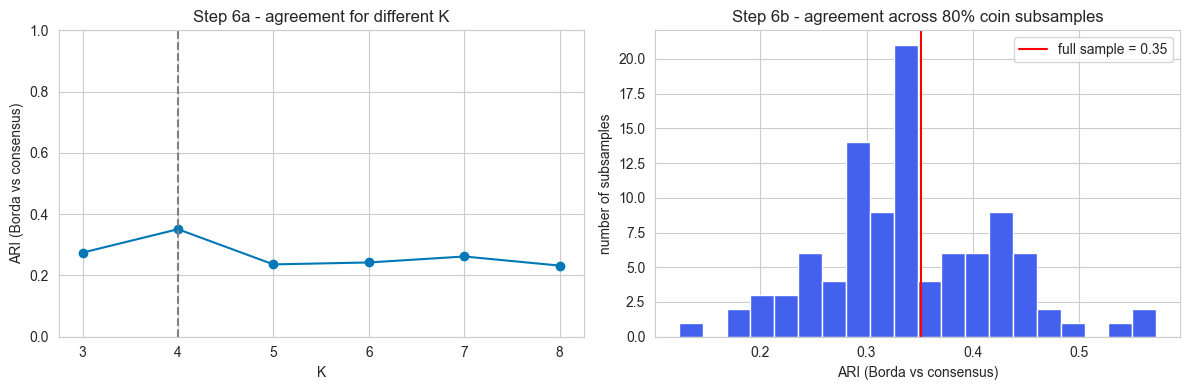

Z-score average vs Borda     ARI = 0.533
Z-score average vs Consensus ARI = 0.460
Z-score cluster sizes: [252, 215, 117, 31]


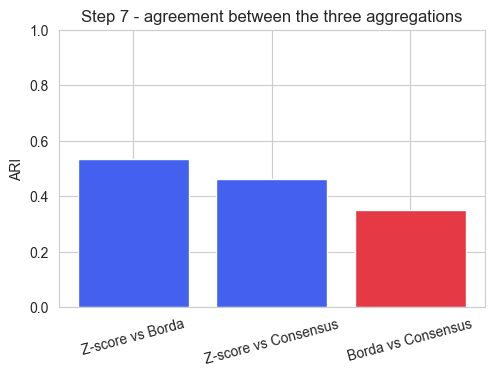

Returns: 1823 days x 615 coins.  Market proxy for HMM (Bitcoin) = bitcoin
Bear days: 246 of 1823

Gap (within minus between):
measure             bear_day_corr  lower_tail  pearson
clustering                                            
Borda                      0.0683      0.0955   0.0750
Consensus                  0.0399      0.0419  -0.0007
Z-score average            0.0411      0.0663   0.0230
Copula only                0.0961      0.1186   0.1087
HMM only                   0.0532      0.0222   0.0748
GLASSO only                0.0252      0.0480   0.0234
DTW only                   0.0516      0.0521   0.0102
Cointegration only         0.0028     -0.0220  -0.0116

Permutation p-values:
measure             bear_day_corr  lower_tail  pearson
clustering                                            
Borda                      0.0050       0.005   0.0050
Consensus                  0.0050       0.005   0.6020
Z-score average            0.0050       0.005   0.0050
Copula only               

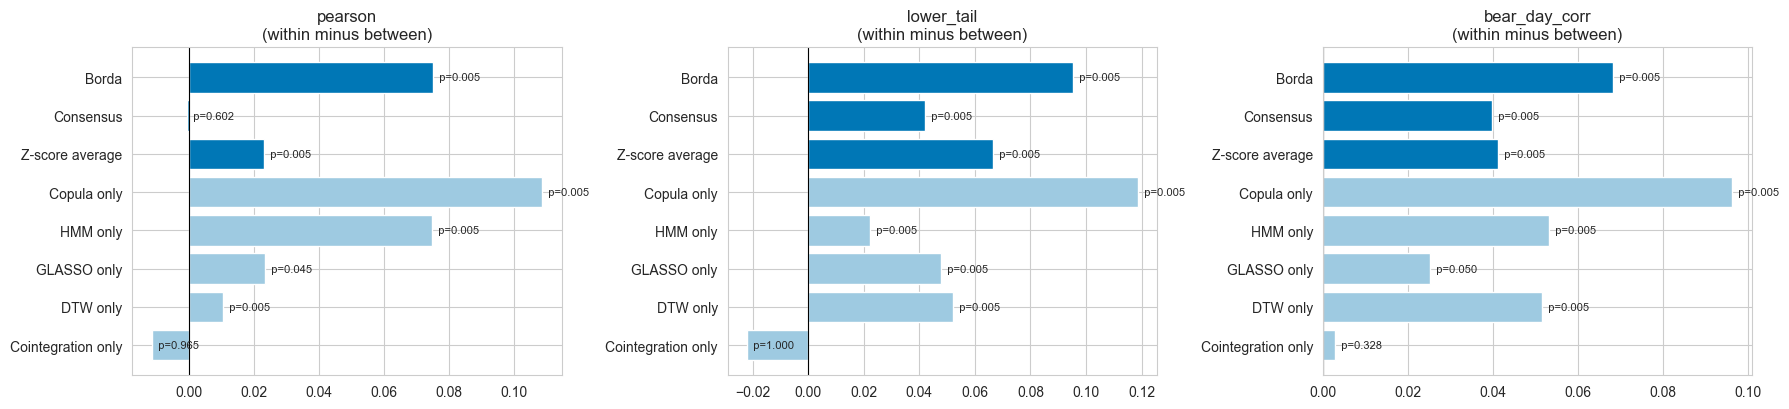

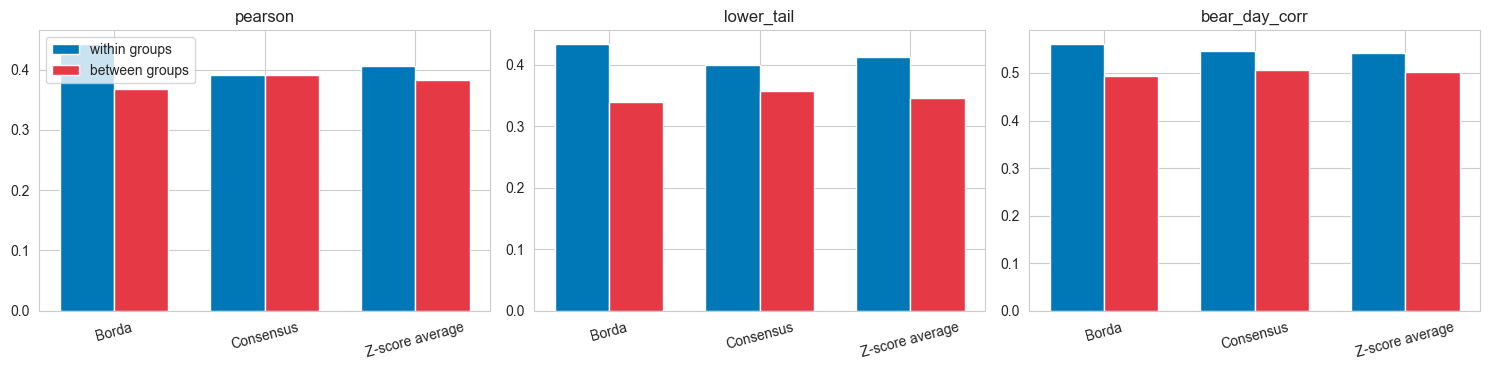


Verdict: aggregations with gap > 0 and p < 0.05
  pearson       : 2 of 3  ['Borda', 'Z-score average']
  lower_tail    : 3 of 3  ['Borda', 'Consensus', 'Z-score average']
  bear_day_corr : 3 of 3  ['Borda', 'Consensus', 'Z-score average']
SUMMARY
- Borda reproduced from the five matrices (max difference 2.9e-04).
- Borda vs consensus ARI = 0.351; across subsamples mean 0.341, 95% interval [0.187, 0.518]; across K = 3..8 the range is 0.23 to 0.35.
- 56% of coins sit in a matched Borda/consensus group.
- Z-score average vs Borda ARI = 0.533.
- pearson: within-group dependence exceeds between-group in 2 of 3 aggregations (p < 0.05).
- lower_tail: within-group dependence exceeds between-group in 3 of 3 aggregations (p < 0.05).
- bear_day_corr: within-group dependence exceeds between-group in 3 of 3 aggregations (p < 0.05).

All tables and figures saved in publication_outputs/point1/


In [3]:
# %% [markdown]
# # Point 1 - Is the Borda composite robust to another way of combining the five methods?
#
# Claim to validate: Borda is the primary, transparent aggregation, and the conclusions
# remain robust under an alternative way of combining the five similarity views.
#
# Steps
# 0. Load the five matrices and the Borda composite
# 1. Why ranks? Show that the five methods are on different scales
# 2. Rebuild Borda from scratch and check it matches the saved composite
# 3. Cluster each method on its own (K = 4)
# 4. Build the consensus (co-association) matrix and cluster it
# 5. Compare Borda groups with consensus groups
# 6. Is the level of agreement stable? (K sweep and coin bootstrap)
# 7. A second alternative: z-score average
# 8. Do the main conclusions hold under each aggregation? (needs returns)
# 9. Summary and saved tables

# %%
# STEP 0 - setup and loading
# Run from the research/ folder (the one that contains similarity_outputs/).
import os, warnings
os.environ["LOKY_MAX_CPU_COUNT"] = "4"      # silences the joblib core-count message on Windows
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle
from scipy import stats
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import squareform
from sklearn.metrics import adjusted_rand_score

SIM_DIR   = "similarity_outputs"
OUT       = "publication_outputs/point1"
DATA_PATH = "../data/crypto_with_indicators.parquet"   # same file section 3.4 reads
K         = 4          # number of archetypes in the thesis
TAIL_Q    = 0.10       # tail threshold used in the copula method
SEED      = 42
N_PERM    = 200        # label permutations for p-values (Step 8)
N_BOOT    = 100        # coin subsamples (Step 6)

os.makedirs(OUT, exist_ok=True)
rng = np.random.default_rng(SEED)
sns.set_style("whitegrid")

FILES = {
    "Copula":        "copula_ltdc_matrix.csv",
    "HMM":           "hmm_similarity_matrix.csv",
    "GLASSO":        "glasso_similarity_matrix.csv",
    "DTW":           "dtw_similarity_matrix.csv",
    "Cointegration": "coint_similarity_matrix.csv",
}
mats = {n: pd.read_csv(f"{SIM_DIR}/{f}", index_col=0) for n, f in FILES.items()}
borda_saved = pd.read_csv(f"{SIM_DIR}/composite_similarity_matrix.csv", index_col=0)

# keep only coins that appear in all six matrices, in the same order
coins = [c for c in borda_saved.index if all(c in m.index for m in mats.values())]
mats = {n: m.reindex(index=coins, columns=coins).fillna(0) for n, m in mats.items()}
borda_saved = borda_saved.reindex(index=coins, columns=coins).fillna(0)

N  = len(coins)
iu = np.triu_indices(N, 1)           # positions of the coin pairs (upper triangle)
print(f"{N} coins, {len(iu[0]):,} coin pairs, {len(mats)} methods")


# ---- helper functions used in every step ------------------------------------
def ward_labels(sim, k):
    """Ward clustering on distance = 1 - similarity (same as section 3.5)."""
    d = (1 - sim).clip(lower=0).values.copy()
    d = (d + d.T) / 2
    np.fill_diagonal(d, 0)
    Z = linkage(squareform(d, checks=False), method="ward")
    return pd.Series(fcluster(Z, k, criterion="maxclust"), index=sim.index)


def coassociation(label_list, index):
    """Share of the clusterings that put each pair of coins in the same cluster."""
    C = np.zeros((len(index), len(index)))
    for lab in label_list:
        v = lab.values
        C += (v[:, None] == v[None, :])
    return pd.DataFrame(C / len(label_list), index=index, columns=index)


def borda_matrix(matrices):
    """Equal-weight Borda: rank every pair within each method, average the ranks,
    then turn the average rank back into a 0-1 similarity (same logic as section 3.4)."""
    n = len(next(iter(matrices.values())))
    pos = np.triu_indices(n, 1)
    rank_sum = np.zeros(len(pos[0]))
    for m in matrices.values():
        rank_sum += stats.rankdata(-m.values[pos]) / len(matrices)   # rank 1 = most similar
    sim = 1 - rank_sum / rank_sum.max()
    M = np.zeros((n, n))
    M[pos] = sim
    M = M + M.T
    np.fill_diagonal(M, 1.0)
    idx = next(iter(matrices.values())).index
    return pd.DataFrame(M, index=idx, columns=idx)


def to_matrix(pair_values, index):
    """Put a vector of pair values back into a symmetric matrix."""
    n = len(index)
    M = np.zeros((n, n))
    M[np.triu_indices(n, 1)] = pair_values
    M = M + M.T
    np.fill_diagonal(M, 1.0)
    return pd.DataFrame(M, index=index, columns=index)


def save(fig, name):
    fig.savefig(f"{OUT}/{name}.png", dpi=150, bbox_inches="tight")


# %% [markdown]
# ## Step 1 - Why ranks? The five methods are on different scales
#
# WHAT: look at the similarity values each method gives to the same coin pairs.
# WHY: the thesis uses ranks because the raw numbers are not comparable.
# HOW TO READ:
# - Top row: each histogram has its own x-axis. Different ranges and shapes confirm the problem.
# - Table: "share_at_modal_value" is the share of pairs that have exactly the same value.
#   A high share means many ties (this matters for ranking).
# - Bar chart: how strongly the combined score follows each method. A plain average of the raw
#   numbers lets the widest method dominate. Rank averaging gives a more even influence.

# %%
raw = pd.DataFrame({n: m.values[iu] for n, m in mats.items()})     # rows = coin pairs

desc = pd.DataFrame({
    "min": raw.min(), "median": raw.median(), "max": raw.max(), "std": raw.std(),
    "share_at_modal_value": raw.apply(lambda s: s.value_counts(normalize=True).iloc[0]),
}).round(4)
print(desc.to_string())

fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, (n, col) in zip(axes, raw.items()):
    ax.hist(col, bins=60, color="#4361ee")
    ax.set_title(f"{n}\nstd = {col.std():.3f}")
    ax.set_xlabel("similarity value")
axes[0].set_ylabel("number of pairs")
fig.suptitle("Step 1a - raw similarity values of the five methods (each panel has its own scale)", y=1.05)
save(fig, "step1a_raw_scales"); plt.show()

# influence of each method on a combined score
naive_avg = raw.mean(axis=1)                                          # plain average of raw numbers
rank_avg  = (-raw).rank(axis=0).mean(axis=1)                          # Borda-style rank average
infl = pd.DataFrame({
    "plain average of raw values": {n: stats.spearmanr(naive_avg, raw[n])[0] for n in raw},
    "Borda (rank average)":        {n: stats.spearmanr(-rank_avg, raw[n])[0] for n in raw},
})
print("\nSpearman correlation between the combined score and each method:")
print(infl.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
infl.plot.bar(ax=ax, color=["#e63946", "#0077b6"], rot=0)
ax.set_ylabel("Spearman correlation with the combined score")
ax.set_title("Step 1b - how much each method drives the combined score")
save(fig, "step1b_influence"); plt.show()

spread_naive = infl.iloc[:, 0].max() - infl.iloc[:, 0].min()
spread_borda = infl.iloc[:, 1].max() - infl.iloc[:, 1].min()
print(f"\nSpread of influence (max - min):  plain average = {spread_naive:.3f},  Borda = {spread_borda:.3f}")
print("A smaller spread means the methods count more equally.")


# %% [markdown]
# ## Step 2 - Rebuild Borda from scratch and check it against the saved composite
#
# WHAT: apply the Borda recipe (rank each method, average the ranks, rescale) to the five matrices
#       and compare with composite_similarity_matrix.csv from section 3.4.
# WHY: before testing an alternative we must be sure we understand the main method exactly.
# HOW TO READ: a maximum difference near 0 means the recipe is reproduced exactly.

# %%
borda_re = borda_matrix(mats)
max_diff = np.abs(borda_re.values - borda_saved.values).max()
rho = stats.spearmanr(borda_re.values[iu], borda_saved.values[iu])[0]
print(f"Max absolute difference vs saved composite: {max_diff:.2e}")
print(f"Spearman correlation vs saved composite   : {rho:.6f}")
print("OK - Borda reproduced." if max_diff < 1e-6 else "WARNING - the saved composite was built differently.")

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.hist(borda_saved.values[iu], bins=60, color="#7209b7")
ax.set_xlabel("Borda composite similarity"); ax.set_ylabel("number of pairs")
ax.set_title("Step 2 - distribution of the composite")
save(fig, "step2_borda_distribution"); plt.show()


# %% [markdown]
# ## Step 3 - Cluster each method on its own
#
# WHAT: Ward clustering at K = 4 on each of the five matrices separately.
# WHY: consensus clustering starts from these five separate clusterings.
# HOW TO READ: each bar is one method, split into its 4 clusters. A bar with one giant segment
#              means that method finds weak structure (almost everything in one group).

# %%
labels = {n: ward_labels(m, K) for n, m in mats.items()}

# Borda groups: use the thesis file if it exists so the group numbers match the thesis
borda = ward_labels(borda_saved, K)
path = f"{SIM_DIR}/cluster_assignments_K{K}.csv"
if os.path.exists(path):
    a = pd.read_csv(path).set_index("coin_id")["cluster"].reindex(coins)
    if a.notna().all():
        print(f"Recomputed Borda groups vs thesis file, ARI = {adjusted_rand_score(borda, a):.3f}")
        borda = a.astype(int)

sizes = {n: sorted(l.value_counts().values, reverse=True) for n, l in {**labels, "Borda": borda}.items()}
sizes = pd.DataFrame({n: pd.Series(v) for n, v in sizes.items()}).fillna(0).astype(int)
sizes.index = [f"cluster {i+1} (largest first)" for i in range(len(sizes))]
print("\nCluster sizes, largest first:")
print(sizes.to_string())

fig, ax = plt.subplots(figsize=(10, 4))
left = np.zeros(sizes.shape[1])
colors = ["#0077b6", "#4cc9f0", "#f4a261", "#e63946", "#7209b7", "#999999"]
for i in range(len(sizes)):
    vals = sizes.iloc[i].values
    ax.barh(sizes.columns, vals, left=left, color=colors[i % len(colors)], edgecolor="white")
    left += vals
ax.set_xlabel("number of coins")
ax.set_title("Step 3 - cluster sizes for each method (K = 4)")
save(fig, "step3_cluster_sizes"); plt.show()


# %% [markdown]
# ## Step 4 - Consensus (co-association) matrix
#
# WHAT: for every pair of coins, count in how many of the five clusterings they share a cluster.
#       Divide by 5. This is the co-association matrix. Then cluster it into 4 groups.
# WHY: this combines the clustering results instead of the raw pairwise scores (the alternative
#      to Borda named in the publication notes).
# HOW TO READ:
# - Left: how many pairs are put together by 0, 1, 2, 3, 4 or 5 methods.
#   Few pairs at 4-5 means the methods rarely agree on who belongs together.
# - Right: the co-association matrix with coins sorted by consensus cluster.
#   Bright squares on the diagonal = coins that most methods keep together.

# %%
co = coassociation(list(labels.values()), coins)
cons = ward_labels(co, K)

votes = np.round(co.values[iu] * len(labels)).astype(int)
vote_counts = pd.Series(votes).value_counts().reindex(range(len(labels) + 1)).fillna(0).astype(int)
print("Number of pairs by how many methods put them together:")
print(vote_counts.to_string())

order = np.argsort(cons.values, kind="stable")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].bar(vote_counts.index.astype(str), vote_counts.values, color="#4361ee")
axes[0].set_xlabel("number of methods (out of 5) that put the pair together")
axes[0].set_ylabel("number of coin pairs")
axes[0].set_yscale("log")
axes[0].set_title("Step 4a - how often the methods agree")
im = axes[1].imshow(co.values[np.ix_(order, order)], cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Step 4b - co-association matrix (coins sorted by consensus cluster)")
axes[1].set_xticks([]); axes[1].set_yticks([])
plt.colorbar(im, ax=axes[1], fraction=0.046, label="share of methods together")
save(fig, "step4_coassociation"); plt.show()
co.to_csv(f"{OUT}/coassociation_matrix.csv")


# %% [markdown]
# ## Step 5 - Compare Borda groups with consensus groups
#
# WHAT: measure how similar the two sets of groups are.
# WHY: this is the direct test of "do the two aggregation methods give the same archetypes?".
# HOW TO READ:
# - ARI heatmap: 1 = identical groups, 0 = no more similar than random labels.
#   Look at the Borda-Consensus cell and at which single method each one resembles.
# - Counts table: rows are Borda groups, columns are consensus groups. Boxed cells are the best
#   one-to-one match between the two sets of groups. Coins outside the boxes moved group.
# - Share-of-row table: for each Borda group, where its coins went.

# %%
all_lab = {**labels, "Borda": borda, "Consensus": cons}
names = list(all_lab)
ari = pd.DataFrame(index=names, columns=names, dtype=float)
for a_ in names:
    for b_ in names:
        ari.loc[a_, b_] = adjusted_rand_score(all_lab[a_], all_lab[b_])

same_b = (borda.values[:, None] == borda.values[None, :])[iu]
same_c = (cons.values[:, None] == cons.values[None, :])[iu]
pair_agree = (same_b == same_c).mean()
ari_bc = ari.loc["Borda", "Consensus"]
print(f"Borda vs Consensus ARI: {ari_bc:.3f}")
print(f"Share of pairs treated the same way (together or apart): {pair_agree:.1%} "
      "(inflated, because most pairs are 'apart' in both)")

tab = pd.crosstab(borda.rename("Borda group"), cons.rename("Consensus group"))
r, c = linear_sum_assignment(-tab.values)                     # best one-to-one matching
matched = set(zip(tab.index[r], tab.columns[c]))
share_matched = tab.values[r, c].sum() / N
print(f"Coins sitting in a matched cell: {share_matched:.1%}")
core = pd.Series([(b, c_) in matched for b, c_ in zip(borda, cons)], index=coins, name="in_matched_core")

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.heatmap(ari.astype(float), annot=True, fmt=".2f", cmap="RdYlGn", vmin=-0.1, vmax=1, ax=axes[0],
            cbar=False)
axes[0].set_title("Step 5a - Adjusted Rand Index between clusterings")
sns.heatmap(tab, annot=True, fmt="d", cmap="Blues", ax=axes[1], cbar=False)
for (ri, ci) in zip(r, c):
    axes[1].add_patch(Rectangle((ci, ri), 1, 1, fill=False, edgecolor="red", lw=3))
axes[1].set_title("Step 5b - coin counts (red = best one-to-one match)")
sns.heatmap(tab.div(tab.sum(axis=1), axis=0), annot=True, fmt=".0%", cmap="Greens", ax=axes[2], cbar=False)
axes[2].set_title("Step 5c - where each Borda group's coins went")
plt.tight_layout()
save(fig, "step5_borda_vs_consensus"); plt.show()


# %% [markdown]
# ## Step 6 - Is the level of agreement stable?
#
# WHAT: repeat the Borda vs consensus comparison (a) for K = 3..8, (b) on 100 random subsamples
#       containing 80% of the coins (Borda and consensus rebuilt each time).
# WHY: one ARI number could be a lucky or unlucky result for K = 4 and this particular coin set.
# HOW TO READ:
# - Left: if ARI is similar across K, agreement does not depend on choosing K = 4.
# - Right: the histogram is the spread of ARI over subsamples. A narrow histogram means the
#   0.35-type value is a stable property, not noise.

# %%
k_rows = []
for k in range(3, 9):
    lab_k = [ward_labels(m, k) for m in mats.values()]
    cons_k = ward_labels(coassociation(lab_k, coins), k)
    bor_k = ward_labels(borda_saved, k)
    k_rows.append({"K": k, "ARI_borda_vs_consensus": adjusted_rand_score(bor_k, cons_k)})
k_tab = pd.DataFrame(k_rows)
print(k_tab.round(3).to_string(index=False))

print(f"\nRunning {N_BOOT} coin-subsample repeats (this takes a minute or two)...")
boot = []
for b in range(N_BOOT):
    idx = np.sort(rng.choice(N, int(0.8 * N), replace=False))
    sub = {n: m.iloc[idx, idx] for n, m in mats.items()}
    bor_b = ward_labels(borda_matrix(sub), K)
    cons_b = ward_labels(coassociation([ward_labels(m, K) for m in sub.values()],
                                       sub["Copula"].index), K)
    boot.append(adjusted_rand_score(bor_b, cons_b))
boot = np.array(boot)
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Bootstrap ARI: mean {boot.mean():.3f}, 95% interval [{lo:.3f}, {hi:.3f}]")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_tab["K"], k_tab["ARI_borda_vs_consensus"], marker="o", color="#0077b6")
axes[0].axvline(K, color="grey", ls="--"); axes[0].set_ylim(0, 1)
axes[0].set_xlabel("K"); axes[0].set_ylabel("ARI (Borda vs consensus)")
axes[0].set_title("Step 6a - agreement for different K")
axes[1].hist(boot, bins=20, color="#4361ee")
axes[1].axvline(ari_bc, color="red", label=f"full sample = {ari_bc:.2f}")
axes[1].set_xlabel("ARI (Borda vs consensus)"); axes[1].set_ylabel("number of subsamples")
axes[1].set_title("Step 6b - agreement across 80% coin subsamples"); axes[1].legend()
plt.tight_layout()
save(fig, "step6_stability"); plt.show()


# %% [markdown]
# ## Step 7 - A second alternative: z-score average
#
# WHAT: standardise each method (subtract mean, divide by std), average the five, rescale to 0-1,
#       and cluster.
# WHY: ranks throw away how much more similar one pair is than another. Z-scores keep that.
#      If z-score and Borda agree, the choice of "how to put the five on one scale" matters little.
# HOW TO READ: look at the ARI of the z-score groups against Borda and against consensus.

# %%
z = (raw - raw.mean()) / raw.std()
zavg = z.mean(axis=1)
zs = (zavg - zavg.min()) / (zavg.max() - zavg.min())          # rescale to 0-1 like the other matrices
zlab = ward_labels(to_matrix(zs.values, coins), K)

ari_zb = adjusted_rand_score(zlab, borda)
ari_zc = adjusted_rand_score(zlab, cons)
print(f"Z-score average vs Borda     ARI = {ari_zb:.3f}")
print(f"Z-score average vs Consensus ARI = {ari_zc:.3f}")
print("Z-score cluster sizes:", sorted([int(v) for v in zlab.value_counts().values], reverse=True))

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.bar(["Z-score vs Borda", "Z-score vs Consensus", "Borda vs Consensus"],
       [ari_zb, ari_zc, ari_bc], color=["#4361ee", "#4361ee", "#e63946"])
ax.set_ylim(0, 1); ax.set_ylabel("ARI"); plt.xticks(rotation=15)
ax.set_title("Step 7 - agreement between the three aggregations")
save(fig, "step7_three_aggregations"); plt.show()


# %% [markdown]
# ## Step 8 - Do the main conclusions hold under each aggregation?
#
# This is the key test for the publication claim. Groups may differ, but do the conclusions survive?
#
# WHAT: for each clustering, compare coin pairs inside the same group with pairs in different groups.
#   gap = average dependence within groups minus average dependence between groups.
#   A good grouping has a clearly positive gap. P-values come from shuffling the group labels.
# Measures: Pearson correlation, lower-tail dependence (co-crash), and correlation on HMM bear days.
# (Bitcoin is only used here as the market proxy that defines the HMM bear days.)
#
# HOW TO READ:
# - Dark bars are the three aggregations (Borda, Consensus, Z-score). Light bars are single methods.
# - If all three dark bars are positive with small p-values, the conclusion is robust to aggregation.
# - Caution: this uses the same data that built the groups (in-sample). A single method will look
#   best on its own measure by construction (e.g. Copula on tail dependence). The out-of-sample
#   test is point 2.

# %%
# --- load returns (same recipe as section 3.4) --------------------------------
df = pd.read_parquet(DATA_PATH, columns=["date", "coin_id", "symbol", "close",
                                         "market_cap_usd", "is_stablecoin"])
df["date"] = pd.to_datetime(df["date"])
df = df[df["is_stablecoin"] == False].sort_values(["coin_id", "date"])
df["log_ret"] = df.groupby("coin_id")["close"].transform(lambda x: np.log(x / x.shift(1)))
ret = df.pivot_table(index="date", columns="coin_id", values="log_ret").reindex(columns=coins)

info = df.groupby("coin_id").agg(symbol=("symbol", "first"), mc=("market_cap_usd", "last"))
btc = info[(info["symbol"].str.upper() == "BTC") & info.index.isin(coins)]["mc"].idxmax()
sym = info["symbol"].to_dict()
print(f"Returns: {ret.shape[0]} days x {ret.shape[1]} coins.  Market proxy for HMM (Bitcoin) = {btc}")


# --- dependence measures on the whole period -----------------------------------
def lower_tail_matrix(r, q=TAIL_Q, min_obs=30):
    """Share of days both coins are in their worst q fraction, divided by q (as in section 3.4)."""
    valid = r.notna()
    u = r.rank() / (valid.sum() + 1)
    ind = (u <= q).astype(float).values
    v = valid.astype(float).values
    nobs = v.T @ v
    m = (ind.T @ ind) / np.maximum(nobs, 1) / q
    m[nobs < min_obs] = np.nan
    np.fill_diagonal(m, 1.0)
    return pd.DataFrame(m, index=r.columns, columns=r.columns)


def bear_day_mask(r, btc_id):
    """Days labelled 'bear' (lowest-mean state) by a 3-state HMM on Bitcoin, as in section 3.4."""
    try:
        from hmmlearn.hmm import GaussianHMM
    except ImportError:
        return None
    x = r[btc_id].dropna()
    m = GaussianHMM(n_components=3, covariance_type="full", n_iter=200,
                    random_state=SEED).fit(x.values.reshape(-1, 1))
    state = m.predict(x.values.reshape(-1, 1))
    return pd.Series(state == np.argmin(m.means_.ravel()), index=x.index)


frames = {"pearson": ret.corr(min_periods=30), "lower_tail": lower_tail_matrix(ret)}
bear = bear_day_mask(ret, btc)
if bear is not None:
    sel = bear.reindex(ret.index).fillna(False).values.astype(bool)
    frames["bear_day_corr"] = ret.loc[sel].corr(min_periods=20)
    print(f"Bear days: {sel.sum()} of {len(sel)}")
else:
    print("hmmlearn not installed - skipping the bear-day measure.")


def within_between(M, lab, n_perm=N_PERM, seed=SEED):
    common = M.index.intersection(lab.index)
    M = M.loc[common, common]
    l = lab.loc[common].values
    pos = np.triu_indices(len(l), 1)
    v = M.values[pos]
    ok = ~np.isnan(v)

    def means(x):
        same = x[pos[0]] == x[pos[1]]
        return v[ok & same].mean(), v[ok & ~same].mean()

    w, b = means(l)
    perm_rng = np.random.default_rng(seed)
    perm = np.array([np.subtract(*means(perm_rng.permutation(l))) for _ in range(n_perm)])
    p = (np.sum(perm >= (w - b)) + 1) / (n_perm + 1)
    return w, b, w - b, p


clusterings = {"Borda": borda, "Consensus": cons, "Z-score average": zlab,
               **{f"{n} only": l for n, l in labels.items()}}
aggs = ["Borda", "Consensus", "Z-score average"]

rows = []
for cn, lab in clusterings.items():
    for mn, M in frames.items():
        w, b, g, p = within_between(M, lab)
        rows.append(dict(clustering=cn, measure=mn, within=w, between=b, gap=g, perm_p=p))
res = pd.DataFrame(rows)
res.to_csv(f"{OUT}/step8_within_between.csv", index=False)

print("\nGap (within minus between):")
print(res.pivot(index="clustering", columns="measure", values="gap").loc[list(clusterings)].round(4).to_string())
print("\nPermutation p-values:")
print(res.pivot(index="clustering", columns="measure", values="perm_p").loc[list(clusterings)].round(4).to_string())

# figure: gaps
measures = list(frames)
fig, axes = plt.subplots(1, len(measures), figsize=(6 * len(measures), 4.2), sharey=False)
axes = np.atleast_1d(axes)
for ax, mn in zip(axes, measures):
    sub = res[res.measure == mn].set_index("clustering").loc[list(clusterings)]
    cols = ["#0077b6" if c in aggs else "#9ecae1" for c in sub.index]
    ax.barh(sub.index, sub["gap"], color=cols)
    for i, (g, p) in enumerate(zip(sub["gap"], sub["perm_p"])):
        ax.text(g, i, f"  p={p:.3f}", va="center", fontsize=8)
    ax.axvline(0, color="black", lw=0.8)
    ax.invert_yaxis()
    ax.set_title(f"{mn}\n(within minus between)")
plt.tight_layout()
save(fig, "step8a_gaps"); plt.show()

# figure: within vs between levels for the three aggregations
fig, axes = plt.subplots(1, len(measures), figsize=(5 * len(measures), 3.8))
axes = np.atleast_1d(axes)
for ax, mn in zip(axes, measures):
    sub = res[(res.measure == mn) & res.clustering.isin(aggs)].set_index("clustering").loc[aggs]
    x = np.arange(len(aggs))
    ax.bar(x - 0.18, sub["within"], 0.36, label="within groups", color="#0077b6")
    ax.bar(x + 0.18, sub["between"], 0.36, label="between groups", color="#e63946")
    ax.set_xticks(x); ax.set_xticklabels(aggs, rotation=15)
    ax.set_title(mn)
axes[0].legend()
plt.tight_layout()
save(fig, "step8b_within_vs_between"); plt.show()

# verdict per measure
print("\nVerdict: aggregations with gap > 0 and p < 0.05")
for mn in measures:
    sub = res[(res.measure == mn) & res.clustering.isin(aggs)]
    ok = sub[(sub.gap > 0) & (sub.perm_p < 0.05)]["clustering"].tolist()
    print(f"  {mn:14s}: {len(ok)} of {len(aggs)}  {ok}")


# %% [markdown]
# ## Step 9 - Summary and saved tables
# Prints the numbers to quote and saves a coin-level table with every grouping.

# %%
coin_table = pd.DataFrame({"symbol": [sym.get(c, c) for c in coins],
                           "borda": borda.values, "consensus": cons.values,
                           "zscore_avg": zlab.values, "in_matched_core": core.values},
                          index=pd.Index(coins, name="coin_id"))
for n, l in labels.items():
    coin_table[f"{n.lower()}_only"] = l.values
coin_table.to_csv(f"{OUT}/coin_groupings.csv")
ari.to_csv(f"{OUT}/ari_matrix.csv")
k_tab.to_csv(f"{OUT}/k_sweep.csv", index=False)
pd.Series(boot, name="ari").to_csv(f"{OUT}/bootstrap_ari.csv", index=False)

print("SUMMARY")
print(f"- Borda reproduced from the five matrices (max difference {max_diff:.1e}).")
print(f"- Borda vs consensus ARI = {ari_bc:.3f}; across subsamples mean {boot.mean():.3f}, "
      f"95% interval [{lo:.3f}, {hi:.3f}]; across K = 3..8 the range is "
      f"{k_tab['ARI_borda_vs_consensus'].min():.2f} to {k_tab['ARI_borda_vs_consensus'].max():.2f}.")
print(f"- {share_matched:.0%} of coins sit in a matched Borda/consensus group.")
print(f"- Z-score average vs Borda ARI = {ari_zb:.3f}.")
for mn in measures:
    sub = res[(res.measure == mn) & res.clustering.isin(aggs)]
    ok = ((sub.gap > 0) & (sub.perm_p < 0.05)).sum()
    print(f"- {mn}: within-group dependence exceeds between-group in {ok} of {len(aggs)} aggregations (p < 0.05).")
print(f"\nAll tables and figures saved in {OUT}/")
